In [1]:
import numpy as np
from scipy.stats import weibull_min

rnd = np.random.default_rng(seed=1235)
X_weib = weibull_min.rvs(c=1, size=30, random_state=rnd)

X = X_weib.copy()
X.sort()
X

array([0.03137465, 0.04531734, 0.06544178, 0.12135278, 0.1791247 ,
       0.19538249, 0.20266212, 0.30067117, 0.31516295, 0.31756893,
       0.34691501, 0.34702768, 0.41694743, 0.43383668, 0.50926666,
       0.53299031, 0.53517583, 0.55862447, 0.88995173, 0.89984881,
       1.04866232, 1.07977963, 1.13848816, 1.17957629, 1.33374016,
       1.33785406, 1.35656268, 1.7545202 , 1.82080282, 1.89182818])

In [2]:
np.any(X[1:] == X[:-1])

np.False_

In [3]:
from statsmodels.distributions import ECDF

ecdf = ECDF(X)

In [4]:
xx = np.r_[0, X]
yy = np.repeat(1 / X.size, X.size)
yy = np.r_[0, yy.cumsum()]

In [5]:
from scipy.interpolate import interp1d

ec = interp1d(xx, yy, kind='previous', bounds_error=False)

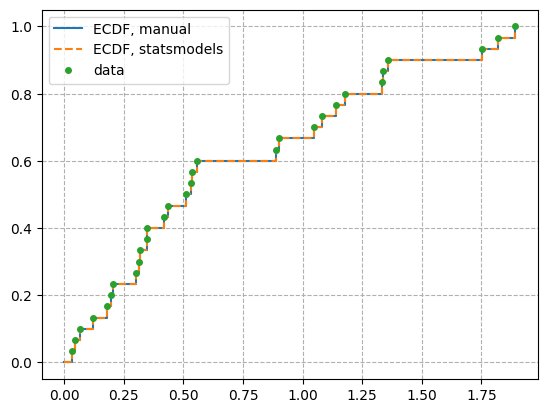

In [27]:
import matplotlib.pyplot as plt

x = np.sort(np.r_[0, X, X - 1e-10, X + 1e-10])

plt.plot(x, ec(x), '-', label='ECDF, manual')
plt.plot(x, ecdf(x), '--', label='ECDF, statsmodels')
plt.plot(X, yy[1:], '.', label='data', ms=8)
plt.grid(ls='--')
plt.legend(loc='best')
plt.show()

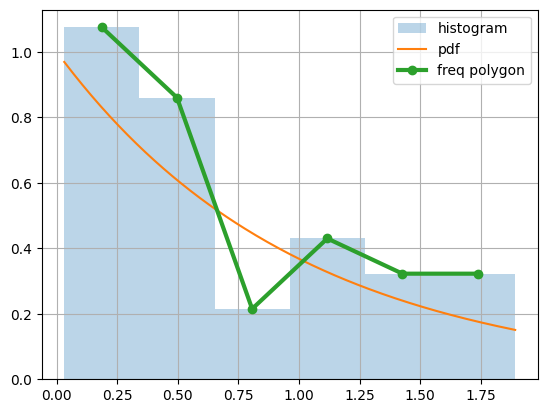

In [7]:
xx = np.linspace(X.min(), X.max(), 201)
hist, bin_edges = np.histogram(X, density='True', bins='auto')
mid = (bin_edges[1:] + bin_edges[:-1]) / 2

plt.hist(X, bins='auto', density=True, alpha=0.3, label='histogram')
plt.plot(xx, weibull_min.pdf(xx, c=1), '-', label='pdf')
plt.plot(mid, hist, 'o-', label='freq polygon', lw=3)
plt.grid(True)
plt.legend(loc='best')
plt.show()

## 3

In [8]:
from scipy.special import gamma

scale = X.sum() / X.size
scale /= gamma(2)

In [25]:
for i in range(20):
    print(i, gamma(i))

0 inf
1 1.0
2 1.0
3 2.0
4 6.0
5 24.0
6 120.0
7 720.0
8 5040.0
9 40320.0
10 362880.0
11 3628800.0
12 39916800.0
13 479001600.0
14 6227020800.0
15 87178291200.0
16 1307674368000.0
17 20922789888000.0
18 355687428096000.0
19 6402373705728000.0


In [9]:
c, loc, scale = weibull_min.fit(X)
print(c, loc, scale)

0.9768878353509471 0.031374654994178505 0.6711446161598695


In [10]:
c, loc, scale = weibull_min.fit(X, floc=0, fc=1)
print(c, loc, scale)

1 0 0.7061934277849369
